# ML Network Intrusion Detector
### Classifying Network Traffic as Benign or Malicious using Scikit-learn

**Author:** Anagha  
**Dataset:** NSL-KDD (KDDTrain+ / KDDTest+)  
**Tools:** Python · Pandas · NumPy · Scikit-learn · Matplotlib · Seaborn · joblib

---

## About this Project

Every time your computer connects to the internet, data travels in small packets.
Some of those packets are normal (Benign), but others may be part of attacks (Malicious).
A **Network Intrusion Detection System (IDS)** automatically watches this traffic and raises
an alarm when something suspicious is detected.

In this project we train two machine learning models — **Logistic Regression** (a simple
baseline) and **Random Forest** (a stronger ensemble) — on the famous **NSL-KDD** benchmark
dataset. We follow a strict, leakage-free pipeline, evaluate both models honestly, and save
the best one so it can be reused.

This notebook is beginner-friendly: every code cell has a plain-English explanation above it.
A fixed random seed (`42`) is used throughout so you get the same results every time you run it.

> **Offline analysis only.** This notebook never connects to or monitors any real network.

---
## Step 0 — Install & Import Libraries

We start by making sure every library we need is available, then import them all in one place.
Running this cell first ensures the rest of the notebook works whether you are on a local
machine or Google Colab.

In [1]:
# Install any missing packages (safe to run on Colab or locally)
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "joblib"])

import os, warnings
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline        import Pipeline
from sklearn.compose         import ColumnTransformer
from sklearn.preprocessing   import StandardScaler, OneHotEncoder
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.metrics         import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")

Libraries imported successfully.


---
## Step 1 — Download the NSL-KDD Dataset

### What is NSL-KDD?
NSL-KDD is a cleaned-up version of the original KDD Cup 1999 dataset, created by the
**Canadian Institute for Cybersecurity (University of New Brunswick)**.
It removes duplicate records and has a well-balanced distribution of attack types,
making it one of the most widely used benchmarks for intrusion detection research.

**Official page:** https://www.unb.ca/cic/datasets/nsl.html  
**GitHub mirror used here:** https://github.com/defcom17/NSL_KDD

### Why NSL-KDD instead of CIC-IDS2017?
CIC-IDS2017 is excellent but its raw CSV files total ~3 GB, which is impractical on a
free Colab session (2 GB RAM limit) and slow on a student laptop. NSL-KDD's two key
files are each ~6 MB and load in seconds.

### Files we use

| File | Role |
|------|------|
| `KDDTrain+.txt` | Training data (official split) |
| `KDDTest+.txt`  | Held-out test data (official split, contains unseen attack types) |

### Column names
The `.txt` files have **no header row**. We supply the 42 standard KDD column names
(41 features + 1 label + 1 difficulty score) from the dataset documentation.

### How to get the files
The cell below tries to download them automatically via `urllib`.  
**If the download fails** (e.g., GitHub rate-limit in Colab), follow these steps:
1. Go to https://github.com/defcom17/NSL_KDD
2. Download `KDDTrain+.txt` and `KDDTest+.txt`
3. **Google Colab:** upload both files using the Files panel (folder icon, left sidebar)
4. **Local machine:** place both files in the same folder as this notebook
5. Re-run this cell — it will detect the local files and skip the download

In [2]:
import urllib.request

# Official 42 column names from NSL-KDD documentation
COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes',
    'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
    'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
    'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
    'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty_level'
]

TRAIN_URL  = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
TEST_URL   = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"
TRAIN_FILE = "KDDTrain+.txt"
TEST_FILE  = "KDDTest+.txt"

def download_if_missing(url, filename):
    if os.path.exists(filename):
        print(f"  '{filename}' already present — skipping download.")
    else:
        print(f"  Downloading '{filename}' ...")
        try:
            urllib.request.urlretrieve(url, filename)
            print(f"  '{filename}' downloaded successfully.")
        except Exception as e:
            print(f"  Download failed: {e}")
            print(f"  Please download manually from: {url}")
            print(f"  and place '{filename}' in this folder, then re-run.")

download_if_missing(TRAIN_URL, TRAIN_FILE)
download_if_missing(TEST_URL,  TEST_FILE)

  'KDDTrain+.txt' downloaded successfully.
  'KDDTest+.txt' downloaded successfully.


In [3]:
# Load train and test files into DataFrames.
# We supply column names manually because the files have no header row.

df_train_raw = pd.read_csv(TRAIN_FILE, header=None, names=COLUMNS)
df_test_raw  = pd.read_csv(TEST_FILE,  header=None, names=COLUMNS)

print("Train shape :", df_train_raw.shape)
print("Test  shape :", df_test_raw.shape)
df_train_raw.head(3)

Train shape : (125973, 43)
Test  shape : (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


---
## Step 2 — Exploratory Data Analysis (EDA)

Before building any model, we need to *understand* the data:
- **Shape** — how many rows and columns?
- **Data types** — which columns are numbers, which are text (categorical)?
- **Missing values** — are there any gaps?
- **Class distribution** — are Benign and Malicious traffic samples roughly balanced?
- **Attack types** — what kinds of attacks exist in both splits?

We will also convert the multi-class label (dozens of attack names) to a **binary label**:
`0 = Benign`, `1 = Malicious`. This makes the problem simpler and more practical.

In [4]:
# Basic info: shape, column names, data types, memory usage
print("=" * 60)
print("TRAINING SET")
print("=" * 60)
print(f"Rows: {df_train_raw.shape[0]:,}   Columns: {df_train_raw.shape[1]}")
print()
df_train_raw.info(memory_usage='deep')
print()
print("Sample rows:")
df_train_raw.head(3)

TRAINING SET
Rows: 125,973   Columns: 43

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised 

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [5]:
# Check for missing values and duplicates in both files.
# 'Missing value' = an empty cell (NaN).
# 'Duplicate'     = an identical row appearing more than once.

print("--- Missing values (train) ---")
train_missing = df_train_raw.isnull().sum()
print(train_missing[train_missing > 0] if train_missing.any() else "None found")

print("\n--- Missing values (test) ---")
test_missing = df_test_raw.isnull().sum()
print(test_missing[test_missing > 0] if test_missing.any() else "None found")

print("\n--- Duplicates ---")
print(f"Train duplicates : {df_train_raw.duplicated().sum():,}")
print(f"Test  duplicates : {df_test_raw.duplicated().sum():,}")

--- Missing values (train) ---
None found

--- Missing values (test) ---
None found

--- Duplicates ---
Train duplicates : 0
Test  duplicates : 0


In [6]:
# Show all unique attack / traffic types present in each split.
# NSL-KDD has 4 main attack categories: DoS, Probe, R2L, U2R.
# 'normal' means benign traffic.

print("Unique labels in KDDTrain+ :")
print(sorted(df_train_raw['label'].unique()))

print("\nUnique labels in KDDTest+ :")
print(sorted(df_test_raw['label'].unique()))

Unique labels in KDDTrain+ :
['back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'imap', 'ipsweep', 'land', 'loadmodule', 'multihop', 'neptune', 'nmap', 'normal', 'perl', 'phf', 'pod', 'portsweep', 'rootkit', 'satan', 'smurf', 'spy', 'teardrop', 'warezclient', 'warezmaster']

Unique labels in KDDTest+ :
['apache2', 'back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'httptunnel', 'imap', 'ipsweep', 'land', 'loadmodule', 'mailbomb', 'mscan', 'multihop', 'named', 'neptune', 'nmap', 'normal', 'perl', 'phf', 'pod', 'portsweep', 'processtable', 'ps', 'rootkit', 'saint', 'satan', 'sendmail', 'smurf', 'snmpgetattack', 'snmpguess', 'sqlattack', 'teardrop', 'udpstorm', 'warezmaster', 'worm', 'xlock', 'xsnoop', 'xterm']


In [7]:
# Convert multi-class label to binary label.
#   'normal'       -> 0  (Benign)
#   everything else -> 1  (Malicious)
# Malicious = 1 is the positive class throughout this notebook.

def make_binary(df):
    df = df.copy()
    df['binary_label'] = (df['label'] != 'normal').astype(int)
    return df

df_train_raw = make_binary(df_train_raw)
df_test_raw  = make_binary(df_test_raw)

# Report class distribution in code (row counts and percentages come from the data)
for name, df in [("KDDTrain+", df_train_raw), ("KDDTest+", df_test_raw)]:
    counts = df['binary_label'].value_counts().sort_index()
    total  = len(df)
    print(f"{name}:")
    print(f"  Benign    (0): {counts[0]:>7,}  ({100*counts[0]/total:.1f}%)")
    print(f"  Malicious (1): {counts[1]:>7,}  ({100*counts[1]/total:.1f}%)")
    print()

KDDTrain+:
  Benign    (0):  67,343  (53.5%)
  Malicious (1):  58,630  (46.5%)

KDDTest+:
  Benign    (0):   9,711  (43.1%)
  Malicious (1):  12,833  (56.9%)



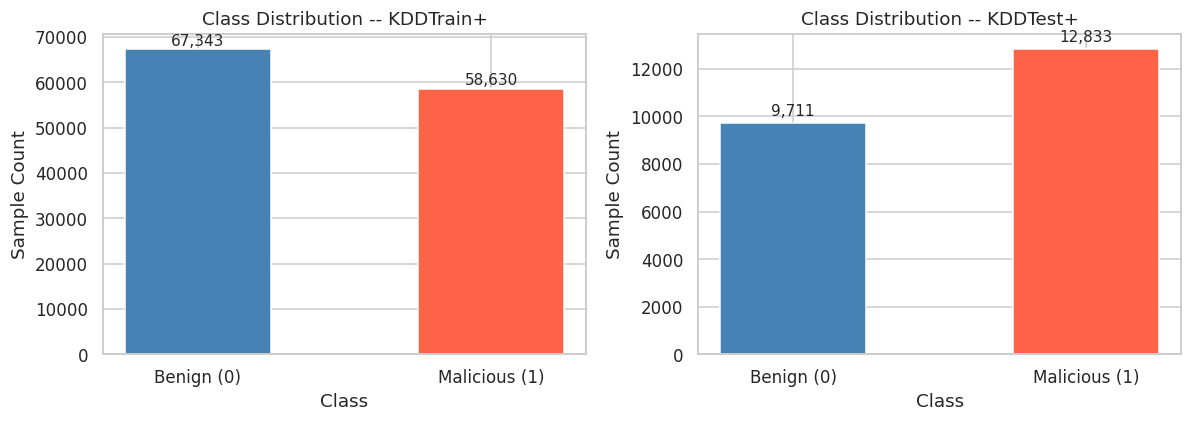

Figure saved as class_distribution.png


In [8]:
# Bar chart: class distribution in both splits side by side.
# This shows whether the dataset is balanced or skewed.

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, df) in zip(axes, [("KDDTrain+", df_train_raw), ("KDDTest+", df_test_raw)]):
    counts = df['binary_label'].value_counts().sort_index()
    bars = ax.bar(["Benign (0)", "Malicious (1)"], counts.values,
                  color=["steelblue", "tomato"], edgecolor="white", width=0.5)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                f"{val:,}", ha='center', va='bottom', fontsize=10)
    ax.set_title(f"Class Distribution -- {name}", fontsize=12)
    ax.set_ylabel("Sample Count")
    ax.set_xlabel("Class")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as class_distribution.png")

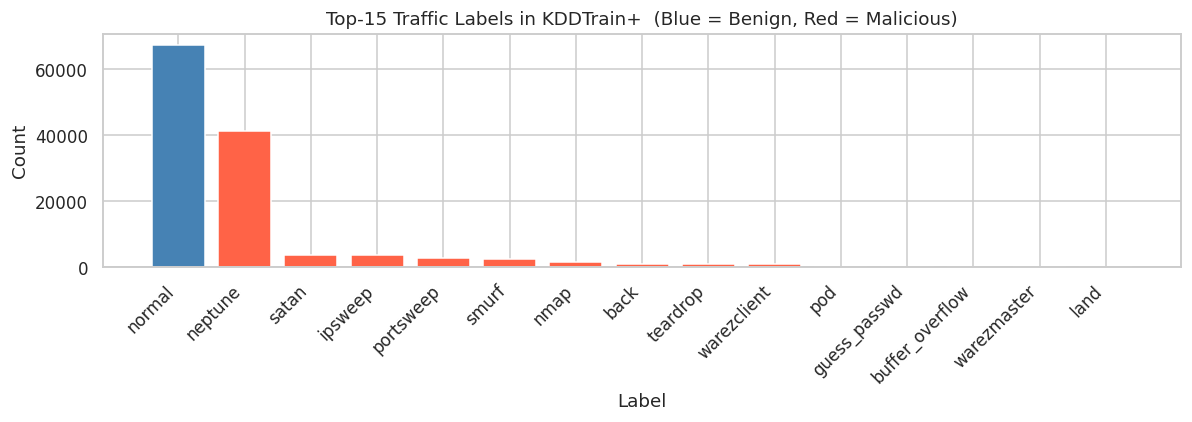

Figure saved as attack_types.png


In [9]:
# Bar chart: top-15 original attack types in KDDTrain+ (including 'normal').
# Blue = Benign, Red = any attack type.

top_labels = df_train_raw['label'].value_counts().head(15)

plt.figure(figsize=(11, 4))
colors = ["steelblue" if lbl == "normal" else "tomato" for lbl in top_labels.index]
plt.bar(top_labels.index, top_labels.values, color=colors, edgecolor="white")
plt.title("Top-15 Traffic Labels in KDDTrain+  (Blue = Benign, Red = Malicious)", fontsize=12)
plt.xlabel("Label")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("attack_types.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as attack_types.png")

### Feature Groups -- Plain English

NSL-KDD has 41 features split into four groups:

| Group | Examples | What they measure |
|-------|---------|-------------------|
| **Basic** | `duration`, `src_bytes`, `dst_bytes` | How long the connection lasted; bytes sent/received |
| **Content** | `logged_in`, `num_failed_logins`, `root_shell` | Whether a login succeeded; suspicious commands inside the connection |
| **Traffic (time-window)** | `count`, `serror_rate`, `rerror_rate` | Connections to the same host in the last 2 seconds; error rates |
| **Host-based** | `dst_host_count`, `dst_host_same_srv_rate` | Statistics over the last 100 connections to the destination host |

**Categorical features** (text): `protocol_type` (tcp/udp/icmp), `service` (http/ftp/...), `flag` (SF/S0/REJ/...).  
**Numerical features**: all remaining 38 columns.

---
## Step 3 -- Preprocessing

Raw data is rarely clean enough to feed directly into a model. We need to:

1. **Drop columns we do not need** -- `difficulty_level` is metadata added by the dataset
   authors, not a real network feature. `num_outbound_cmds` is constant (all zeros).
2. **Handle infinite values** -- Some numeric features can be `inf` (rate columns where
   the denominator was zero). Replace with `NaN`, then fill with the column median
   computed on training data only.
3. **Remove duplicates** from the training set.
4. **Build a ColumnTransformer** -- Apply `OneHotEncoder` to the 3 categorical columns
   and `StandardScaler` to all numeric columns, all inside a `Pipeline`.
   The scaler's mean and std are learned only on training data (**no data leakage**).
5. **Validation split** -- 80/20 stratified split of `KDDTrain+` for choosing between
   models without touching `KDDTest+`.

### Why drop `difficulty_level`?
It was added by the NSL-KDD authors to label how hard each sample is to classify.
It is not a real network feature -- no real IDS sensor would ever see it. Including it
would be cheating (label leakage).

### Why drop `num_outbound_cmds`?
A column that is the same value for every row tells the model nothing useful.
It just adds noise and wastes memory.

In [10]:
# Drop columns that must not be used as features.
# 'difficulty_level' is metadata. 'label' is the original multi-class target.

COLS_TO_DROP = ['difficulty_level', 'label']

df_train = df_train_raw.drop(columns=COLS_TO_DROP).copy()
df_test  = df_test_raw.drop(columns=COLS_TO_DROP).copy()

# Identify constant columns (std == 0 across the training set) and drop them
numeric_cols_check = df_train.select_dtypes(include=[np.number]).drop(columns=['binary_label'])
constant_cols = numeric_cols_check.columns[numeric_cols_check.std() == 0].tolist()
print(f"Constant columns found in train (dropped): {constant_cols}")

df_train = df_train.drop(columns=constant_cols)
df_test  = df_test.drop(columns=constant_cols)

print(f"\nTrain shape after drops: {df_train.shape}")
print(f"Test  shape after drops: {df_test.shape}")

Constant columns found in train (dropped): ['num_outbound_cmds']

Train shape after drops: (125973, 41)
Test  shape after drops: (22544, 41)


In [11]:
# Replace infinite values with NaN, then fill NaN with column medians.
# IMPORTANT: medians are computed ONLY on the training set, then applied to the test set.
# This prevents data leakage -- the model never 'sees' test-set statistics.

FEATURE_COLS = [c for c in df_train.columns if c != 'binary_label']

for col in FEATURE_COLS:
    if df_train[col].dtype.kind in ('f', 'i', 'u'):   # float or integer columns
        df_train[col] = df_train[col].replace([np.inf, -np.inf], np.nan)
        df_test[col]  = df_test[col].replace([np.inf, -np.inf], np.nan)

train_medians = df_train[FEATURE_COLS].median(numeric_only=True)
df_train[FEATURE_COLS] = df_train[FEATURE_COLS].fillna(train_medians)
df_test[FEATURE_COLS]  = df_test[FEATURE_COLS].fillna(train_medians)

train_nan = df_train[FEATURE_COLS].isnull().sum().sum()
test_nan  = df_test[FEATURE_COLS].isnull().sum().sum()
print(f"Remaining NaN after fill -- train: {train_nan}  test: {test_nan}")
print("Inf/NaN handling complete.")

Remaining NaN after fill -- train: 0  test: 0
Inf/NaN handling complete.


In [12]:
# Remove duplicate rows from the training set.
# Duplicates can make the model over-confident about common patterns.

before = len(df_train)
df_train = df_train.drop_duplicates()
after  = len(df_train)
print(f"Rows before dedup: {before:,}  |  after: {after:,}  |  removed: {before - after:,}")

Rows before dedup: 125,973  |  after: 125,964  |  removed: 9


In [13]:
# Define feature columns and target, then create the official split and a
# 80/20 validation split from KDDTrain+ (for model selection).
#
# Stratified split: both halves keep the same Benign/Malicious ratio.

CAT_FEATURES = ['protocol_type', 'service', 'flag']
NUM_FEATURES = [c for c in FEATURE_COLS if c not in CAT_FEATURES]

X_train_full = df_train[FEATURE_COLS]
y_train_full = df_train['binary_label']

X_test_official = df_test[FEATURE_COLS]
y_test_official  = df_test['binary_label']

# 80/20 validation split of KDDTrain+
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, random_state=SEED, stratify=y_train_full
)

print(f"X_train_full shape  : {X_train_full.shape}")
print(f"X_test_official shape: {X_test_official.shape}")
print(f"Val split           : train={X_tr.shape[0]:,}  val={X_val.shape[0]:,}")
print(f"Categorical features ({len(CAT_FEATURES)}): {CAT_FEATURES}")
print(f"Numeric  features  ({len(NUM_FEATURES)}): listed above in markdown")

X_train_full shape  : (125964, 40)
X_test_official shape: (22544, 40)
Val split           : train=100,771  val=25,193
Categorical features (3): ['protocol_type', 'service', 'flag']
Numeric  features  (37): listed above in markdown


In [14]:
# Build the ColumnTransformer that sits inside each Pipeline.
#
# OneHotEncoder  -- turns text categories into 0/1 indicator columns.
#                   handle_unknown='ignore' is safe against new category values in test.
# StandardScaler -- rescales numbers to mean=0, std=1 (important for Logistic Regression).
# sparse_output=False keeps the matrix dense (compatible with all estimators).

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
            ('num', StandardScaler(), NUM_FEATURES)
        ],
        remainder='drop'
    )

print("ColumnTransformer factory defined.")

ColumnTransformer factory defined.


---
## Step 4 -- Train the Models

We train **two** models:

| Model | Why include it |
|-------|----------------|
| **Logistic Regression** | Simple, fast, interpretable -- a good *baseline*. |
| **Random Forest** | Ensemble of many decision trees; usually much more accurate on tabular data. |

Both use `class_weight='balanced'` so they pay more attention to whichever class has fewer
samples -- important for fair detection.

### Two evaluation scenarios
1. **Validation split** (80% of KDDTrain+ -> train, 20% -> val): for comparing models
   and choosing hyperparameters **without touching the official test set**.
2. **Official split** (all of KDDTrain+ -> train, KDDTest+ -> test): the final honest evaluation.

> **Rule:** We do NOT use KDDTest+ scores to decide which model is better.
> We use the validation split for that decision.

In [15]:
# Logistic Regression -- validation split
#
# The Pipeline chains: ColumnTransformer -> LogisticRegression.
# fit() learns both the transformer parameters AND the model coefficients from X_tr only.
# predict(X_val) transforms X_val using the learned parameters, then classifies -- no leakage.

print("Training Logistic Regression (validation split)...")
lr_pipe_val = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier',   LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED,
        solver='lbfgs',
        C=1.0
    ))
])
lr_pipe_val.fit(X_tr, y_tr)
print("  Logistic Regression (val split) trained.")

Training Logistic Regression (validation split)...
  Logistic Regression (val split) trained.


In [16]:
# Random Forest -- validation split
#
# n_estimators=100: 100 trees -- good accuracy, runs in ~1-2 minutes.
# max_depth=20: limits depth to prevent overfitting and speed up training.
# n_jobs=-1: use all available CPU cores.

print("Training Random Forest (validation split) -- may take ~1-2 minutes...")
rf_pipe_val = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier',   RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1
    ))
])
rf_pipe_val.fit(X_tr, y_tr)
print("  Random Forest (val split) trained.")

Training Random Forest (validation split) -- may take ~1-2 minutes...
  Random Forest (val split) trained.


In [17]:
# Both models -- official split (trained on all of KDDTrain+)
# These are the final pipelines evaluated against KDDTest+.

print("Training both models on full KDDTrain+ for official evaluation...")

lr_pipe_official = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier',   LogisticRegression(
        class_weight='balanced', max_iter=1000,
        random_state=SEED, solver='lbfgs', C=1.0
    ))
])
lr_pipe_official.fit(X_train_full, y_train_full)
print("  Logistic Regression (official) trained.")

rf_pipe_official = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier',   RandomForestClassifier(
        n_estimators=100, max_depth=20,
        class_weight='balanced',
        random_state=SEED, n_jobs=-1
    ))
])
rf_pipe_official.fit(X_train_full, y_train_full)
print("  Random Forest (official) trained.")

Training both models on full KDDTrain+ for official evaluation...
  Logistic Regression (official) trained.
  Random Forest (official) trained.


---
## Step 5 -- Evaluate the Models

### Metrics -- plain English

| Metric | What it answers |
|--------|-----------------|
| **Accuracy** | Of all predictions, what % were correct? |
| **Precision** | Of all times we predicted Malicious, what % were actually malicious? (Avoid false alarms) |
| **Recall** | Of all actual attacks, what % did we catch? (Avoid missed attacks) |
| **F1-score** | Harmonic mean of Precision and Recall -- one balanced score |
| **ROC-AUC** | At every possible threshold, how well does the model separate classes? 1.0 = perfect, 0.5 = random |

### Why are false negatives (missed attacks) dangerous?
A **false negative** means the model predicted Benign but the traffic was actually an attack.
The attacker slips through undetected. In security, we almost always prefer more false alarms
over missing real attacks. That is why **Recall** is our most important metric.

### Why will KDDTest+ scores be lower?
KDDTest+ contains attack types **not present in KDDTrain+** (novel attack variants added
intentionally by the dataset creators). The model has never seen these patterns, so it
struggles to classify them. This is a realistic simulation of how an IDS performs against
new, evolving threats.

In [18]:
# Helper: compute all metrics for a fitted pipeline.
# positive class = 1 (Malicious) throughout.

def evaluate_model(name, pipeline, X, y_true, split_name):
    y_pred  = pipeline.predict(X)
    y_proba = pipeline.predict_proba(X)[:, 1]

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=1, average='binary', zero_division=0)
    rec  = recall_score(y_true, y_pred, pos_label=1, average='binary', zero_division=0)
    f1   = f1_score(y_true, y_pred, pos_label=1, average='binary', zero_division=0)
    auc  = roc_auc_score(y_true, y_proba)

    print(f"\n{'='*62}")
    print(f"  {name}  |  Split: {split_name}")
    print(f"{'='*62}")
    print(f"  Accuracy  : {acc:.4f}")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1-Score  : {f1:.4f}")
    print(f"  ROC-AUC   : {auc:.4f}")
    print()
    print(classification_report(y_true, y_pred,
          target_names=['Benign (0)', 'Malicious (1)']))

    return {"Model": name, "Split": split_name,
            "Accuracy": acc, "Precision": prec,
            "Recall": rec, "F1": f1, "ROC-AUC": auc,
            "y_pred": y_pred, "y_proba": y_proba}

print("evaluate_model() defined.")

evaluate_model() defined.


In [19]:
# Evaluate on the 20% validation set (used for model selection -- never for final reporting)
res_lr_val = evaluate_model("Logistic Regression", lr_pipe_val, X_val, y_val, "Validation")
res_rf_val = evaluate_model("Random Forest",       rf_pipe_val, X_val, y_val, "Validation")


  Logistic Regression  |  Split: Validation
  Accuracy  : 0.9746
  Precision : 0.9751
  Recall    : 0.9701
  F1-Score  : 0.9726
  ROC-AUC   : 0.9967

               precision    recall  f1-score   support

   Benign (0)       0.97      0.98      0.98     13469
Malicious (1)       0.98      0.97      0.97     11724

     accuracy                           0.97     25193
    macro avg       0.97      0.97      0.97     25193
 weighted avg       0.97      0.97      0.97     25193


  Random Forest  |  Split: Validation
  Accuracy  : 0.9990
  Precision : 0.9996
  Recall    : 0.9982
  F1-Score  : 0.9989
  ROC-AUC   : 1.0000

               precision    recall  f1-score   support

   Benign (0)       1.00      1.00      1.00     13469
Malicious (1)       1.00      1.00      1.00     11724

     accuracy                           1.00     25193
    macro avg       1.00      1.00      1.00     25193
 weighted avg       1.00      1.00      1.00     25193



In [20]:
# Evaluate on the official KDDTest+ (final honest numbers)
res_lr_off = evaluate_model("Logistic Regression", lr_pipe_official,
                             X_test_official, y_test_official, "KDDTest+ (official)")
res_rf_off = evaluate_model("Random Forest",       rf_pipe_official,
                             X_test_official, y_test_official, "KDDTest+ (official)")


  Logistic Regression  |  Split: KDDTest+ (official)
  Accuracy  : 0.7547
  Precision : 0.9170
  Recall    : 0.6258
  F1-Score  : 0.7439
  ROC-AUC   : 0.7910

               precision    recall  f1-score   support

   Benign (0)       0.65      0.93      0.76      9711
Malicious (1)       0.92      0.63      0.74     12833

     accuracy                           0.75     22544
    macro avg       0.78      0.78      0.75     22544
 weighted avg       0.80      0.75      0.75     22544


  Random Forest  |  Split: KDDTest+ (official)
  Accuracy  : 0.7714
  Precision : 0.9677
  Recall    : 0.6190
  F1-Score  : 0.7551
  ROC-AUC   : 0.9648

               precision    recall  f1-score   support

   Benign (0)       0.66      0.97      0.79      9711
Malicious (1)       0.97      0.62      0.76     12833

     accuracy                           0.77     22544
    macro avg       0.81      0.80      0.77     22544
 weighted avg       0.83      0.77      0.77     22544



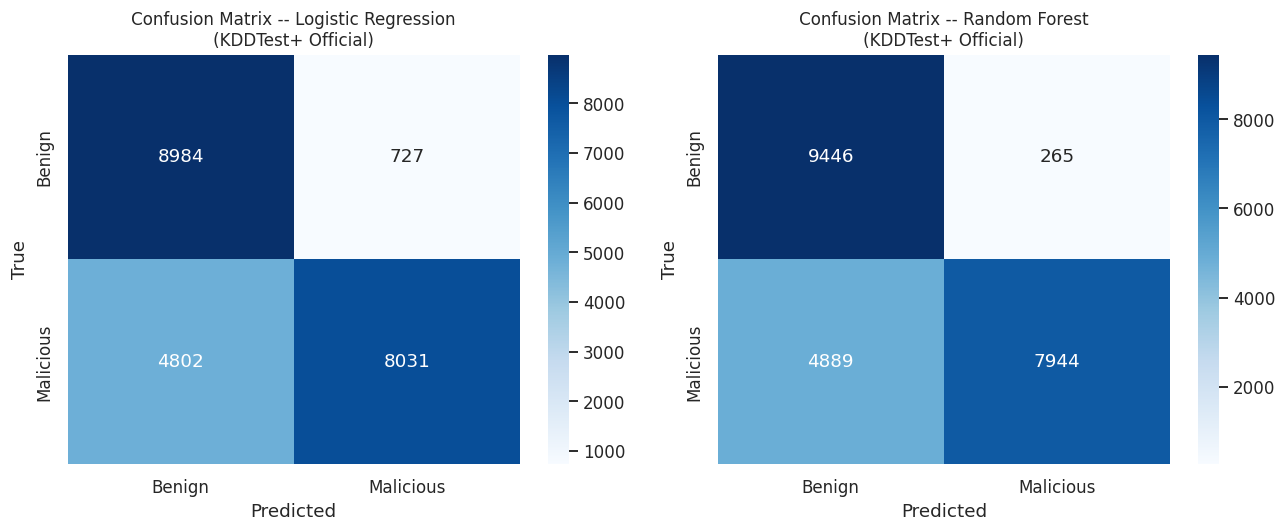

Figure saved as confusion_matrices.png


In [21]:
# Confusion matrix heatmaps for both models on KDDTest+ (official split).
#
# Confusion matrix layout:
#   Top-left  (TN): correctly predicted Benign
#   Top-right (FP): said Malicious, was Benign    (false alarm)
#   Bot-left  (FN): said Benign,    was Malicious  (MISSED ATTACK)
#   Bot-right (TP): correctly predicted Malicious

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
results_off = [res_lr_off, res_rf_off]

for ax, res in zip(axes, results_off):
    cm = confusion_matrix(y_test_official, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Benign', 'Malicious'],
                yticklabels=['Benign', 'Malicious'])
    ax.set_title(f"Confusion Matrix -- {res['Model']}\n(KDDTest+ Official)", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as confusion_matrices.png")

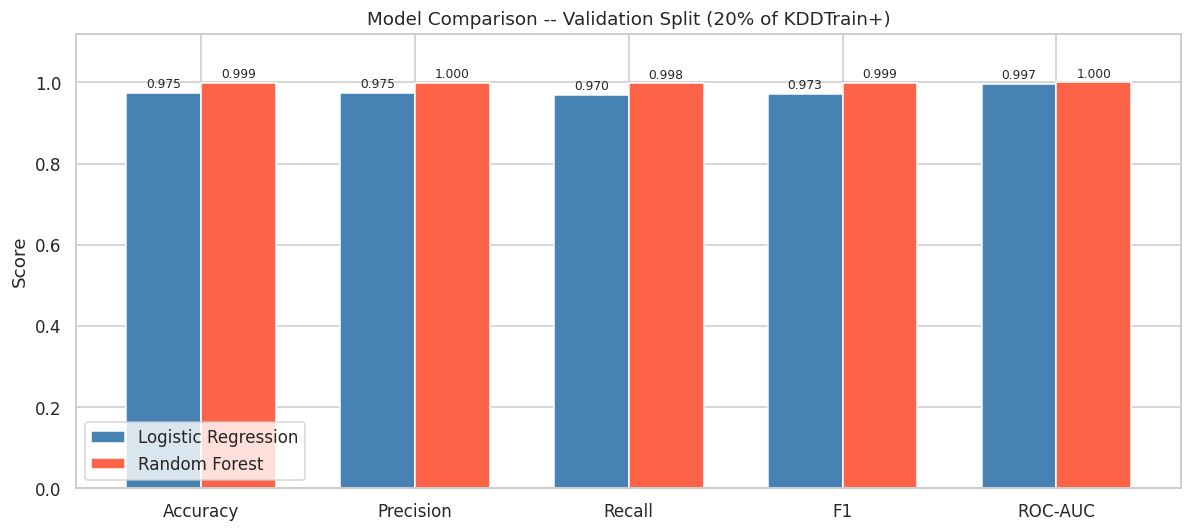

Figure saved as model_comparison.png


In [22]:
# Grouped bar chart: compare both models on all 5 metrics (validation split).
# We use the validation split here -- not the test set -- for fair model selection.

metrics   = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
lr_scores = [res_lr_val[m] for m in metrics]
rf_scores = [res_rf_val[m] for m in metrics]

x     = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - width/2, lr_scores, width, label='Logistic Regression',
               color='steelblue', edgecolor='white')
bars2 = ax.bar(x + width/2, rf_scores, width, label='Random Forest',
               color='tomato', edgecolor='white')

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Model Comparison -- Validation Split (20% of KDDTrain+)", fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as model_comparison.png")

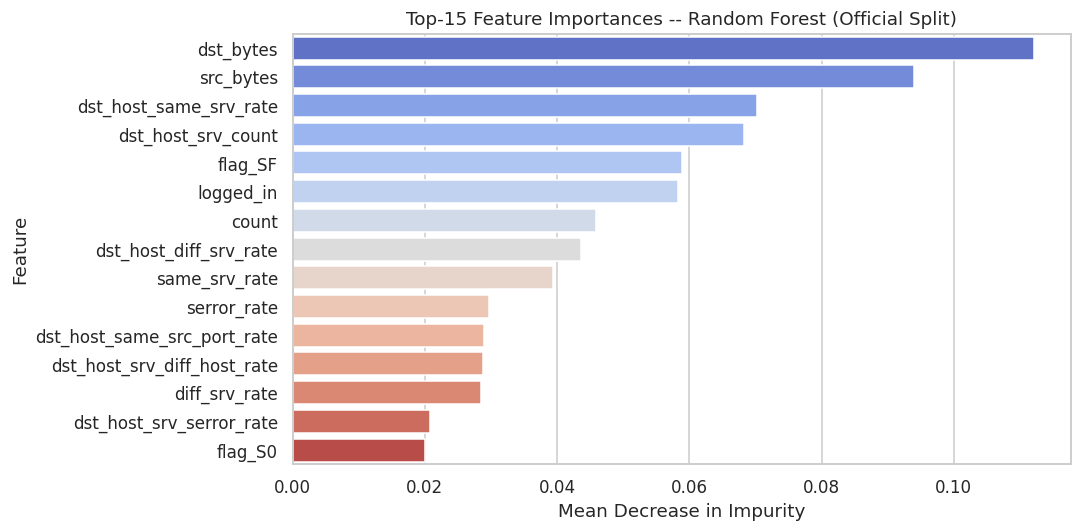

Figure saved as feature_importances.png

                    feature  importance
                  dst_bytes    0.112175
                  src_bytes    0.093917
     dst_host_same_srv_rate    0.070189
         dst_host_srv_count    0.068312
                    flag_SF    0.058873
                  logged_in    0.058297
                      count    0.045932
     dst_host_diff_srv_rate    0.043581
              same_srv_rate    0.039381
                serror_rate    0.029685
dst_host_same_src_port_rate    0.028998
dst_host_srv_diff_host_rate    0.028871
              diff_srv_rate    0.028563
   dst_host_srv_serror_rate    0.020786
                    flag_S0    0.020034


In [23]:
# Top-15 Random Forest feature importances (official-split model).
#
# Feature importance answers: which input features does the forest rely on most?
# We use get_feature_names_out() to get clean labels that include
# OHE-generated column names (e.g., 'cat__protocol_type_tcp').

ct = rf_pipe_official.named_steps['preprocessor']
rf = rf_pipe_official.named_steps['classifier']

feature_names = ct.get_feature_names_out()
importances   = rf.feature_importances_

feat_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feat_df = feat_df.sort_values('importance', ascending=False).head(15).copy()

# Shorten prefixes for readability
feat_df['feature'] = (feat_df['feature']
                      .str.replace('num__', '', regex=False)
                      .str.replace('cat__', '', regex=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=feat_df, x='importance', y='feature', palette='coolwarm', orient='h')
plt.title("Top-15 Feature Importances -- Random Forest (Official Split)", fontsize=12)
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importances.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as feature_importances.png")
print()
print(feat_df[['feature', 'importance']].to_string(index=False))

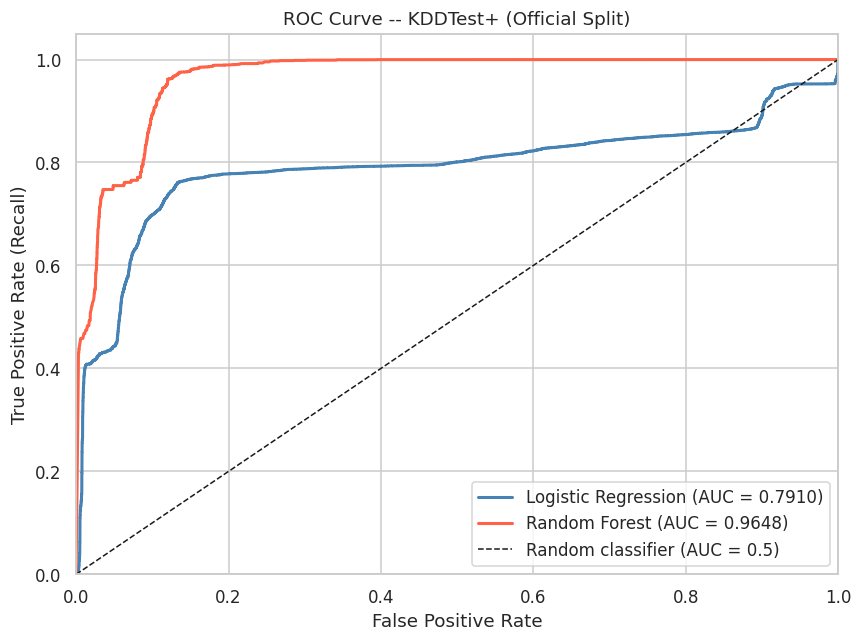

Figure saved as roc_curve.png


In [24]:
# ROC Curve for both models on KDDTest+ (official split).
#
# The ROC curve plots True Positive Rate (Recall) vs False Positive Rate at every threshold.
# A curve that hugs the top-left corner is better. AUC = area under this curve.
# A random classifier traces the diagonal (AUC = 0.5).

plt.figure(figsize=(8, 6))

for res, color in [(res_lr_off, 'steelblue'), (res_rf_off, 'tomato')]:
    fpr, tpr, _ = roc_curve(y_test_official, res['y_proba'])
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f"{res['Model']} (AUC = {res['ROC-AUC']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random classifier (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve -- KDDTest+ (Official Split)", fontsize=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=110, bbox_inches='tight')
plt.show()
print("Figure saved as roc_curve.png")

In [25]:
# Summary table: validation vs official test scores for both models.
# This makes the drop in performance on KDDTest+ clearly visible.

summary = pd.DataFrame([
    {"Model": "Logistic Regression", "Split": "Validation",
     "Accuracy": res_lr_val['Accuracy'], "Precision": res_lr_val['Precision'],
     "Recall": res_lr_val['Recall'],     "F1": res_lr_val['F1'],
     "ROC-AUC": res_lr_val['ROC-AUC']},
    {"Model": "Logistic Regression", "Split": "KDDTest+ (official)",
     "Accuracy": res_lr_off['Accuracy'], "Precision": res_lr_off['Precision'],
     "Recall": res_lr_off['Recall'],     "F1": res_lr_off['F1'],
     "ROC-AUC": res_lr_off['ROC-AUC']},
    {"Model": "Random Forest",       "Split": "Validation",
     "Accuracy": res_rf_val['Accuracy'], "Precision": res_rf_val['Precision'],
     "Recall": res_rf_val['Recall'],     "F1": res_rf_val['F1'],
     "ROC-AUC": res_rf_val['ROC-AUC']},
    {"Model": "Random Forest",       "Split": "KDDTest+ (official)",
     "Accuracy": res_rf_off['Accuracy'], "Precision": res_rf_off['Precision'],
     "Recall": res_rf_off['Recall'],     "F1": res_rf_off['F1'],
     "ROC-AUC": res_rf_off['ROC-AUC']},
])
display(summary.round(4))

,Model,Split,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Validation,0.9746,0.9751,0.9701,0.9726,0.9967
1,Logistic Regression,KDDTest+ (official),0.7547,0.9170,0.6258,0.7439,0.7910
2,Random Forest,Validation,0.9990,0.9996,0.9982,0.9989,1.0000
3,Random Forest,KDDTest+ (official),0.7714,0.9677,0.6190,0.7551,0.9648


### Honest Limitations

1. **Dataset age:** NSL-KDD is derived from 1998/1999 traffic simulations.
   Modern attack techniques (encrypted malware, AI-driven attacks) are not represented.
2. **Unseen attack types:** KDDTest+ intentionally includes attack subtypes not in KDDTrain+.
   The drop in test scores vs. validation scores is expected -- not a bug.
3. **Simulated traffic:** Data comes from a controlled test environment, not real captures.
   Feature distributions may differ from actual enterprise traffic.
4. **Binary simplification:** We collapsed 22+ attack types into one Malicious class.
   A real IDS should also identify the *type* of attack to respond appropriately.
5. **Default threshold:** We use the 0.5 decision threshold. In practice an operator
   would tune this to balance false alarms against missed attacks for their risk tolerance.
6. **No feature engineering:** Raw KDD features are used as-is. Domain-specific engineering
   (payload entropy, inter-arrival times) could significantly improve performance.

---
## Step 6 -- Save, Reload, and Predict

We save the best-performing pipeline (chosen by validation F1 score) using `joblib`.
Then we reload it from disk to prove it works without the training variables in memory.

Finally, we write a `predict_traffic(row)` function that takes a single row of raw
(unscaled) network data and returns `"Benign"` or `"Malicious"` -- exactly what a real
IDS endpoint would do.

In [26]:
# Select the best model by validation-split F1 score (NOT by test-set scores).

os.makedirs("models", exist_ok=True)

lr_val_f1 = res_lr_val['F1']
rf_val_f1 = res_rf_val['F1']

print(f"Validation F1 -- Logistic Regression : {lr_val_f1:.4f}")
print(f"Validation F1 -- Random Forest       : {rf_val_f1:.4f}")

if rf_val_f1 >= lr_val_f1:
    best_pipeline = rf_pipe_official
    best_name     = "Random Forest"
else:
    best_pipeline = lr_pipe_official
    best_name     = "Logistic Regression"

print(f"\nBest model (by validation F1): {best_name}")

joblib.dump(lr_pipe_official, "models/lr_pipeline.pkl")
joblib.dump(rf_pipe_official, "models/rf_pipeline.pkl")
joblib.dump(best_pipeline,    "models/best_pipeline.pkl")

print("\nSaved:")
print("  models/lr_pipeline.pkl")
print("  models/rf_pipeline.pkl")
print("  models/best_pipeline.pkl")

Validation F1 -- Logistic Regression : 0.9726
Validation F1 -- Random Forest       : 0.9989

Best model (by validation F1): Random Forest

Saved:
  models/lr_pipeline.pkl
  models/rf_pipeline.pkl
  models/best_pipeline.pkl


In [27]:
# Reload the best pipeline from disk and predict on 10 real test-set rows.
# Clearing the variable first proves we are genuinely loading from disk.

del best_pipeline

loaded_pipeline = joblib.load("models/best_pipeline.pkl")
print(f"Loaded: models/best_pipeline.pkl")
print(f"Type  : {type(loaded_pipeline.named_steps['classifier']).__name__}")

# Pick 5 Benign and 5 Malicious rows from KDDTest+
sample_rows = X_test_official.copy()
sample_rows['true_label'] = y_test_official.values

sample_benign    = sample_rows[sample_rows['true_label'] == 0].head(5)
sample_malicious = sample_rows[sample_rows['true_label'] == 1].head(5)
sample_10        = pd.concat([sample_benign, sample_malicious]).copy()

X_sample = sample_10.drop(columns=['true_label'])
y_sample = sample_10['true_label'].values

preds  = loaded_pipeline.predict(X_sample)
probas = loaded_pipeline.predict_proba(X_sample)[:, 1]

results_table = pd.DataFrame({
    'True Label'   : ['Benign' if y == 0 else 'Malicious' for y in y_sample],
    'Predicted'    : ['Benign' if p == 0 else 'Malicious' for p in preds],
    'P(Malicious)' : np.round(probas, 4),
    'Correct?'     : ['Yes' if t == p else 'No' for t, p in zip(y_sample, preds)]
})
display(results_table)

Loaded: models/best_pipeline.pkl
Type  : RandomForestClassifier


,True Label,Predicted,P(Malicious),Correct?
0,Benign,Benign,0.0006,Yes
1,Benign,Benign,0.0000,Yes
2,Benign,Benign,0.0413,Yes
3,Benign,Benign,0.0000,Yes
4,Benign,Benign,0.0537,Yes
5,Malicious,Malicious,1.0000,Yes
6,Malicious,Malicious,1.0000,Yes
7,Malicious,Malicious,0.9400,Yes
8,Malicious,Benign,0.3300,No
9,Malicious,Benign,0.1024,No


In [28]:
# predict_traffic(row) -- reusable function for a single network connection record.
#
# Input : a pandas Series or single-row DataFrame with the 40 feature columns.
#         No scaling/encoding needed -- the Pipeline handles that internally.
# Output: the string "Benign" or "Malicious", plus the malicious probability.

def predict_traffic(row):
    '''
    Predict whether a network connection is Benign or Malicious.

    Parameters
    ----------
    row : pd.Series or single-row pd.DataFrame
        Must contain the 40 NSL-KDD feature columns (no target column).

    Returns
    -------
    tuple: (label: str, probability_malicious: float)
    '''
    if isinstance(row, pd.Series):
        row = row.to_frame().T
    row   = row[FEATURE_COLS]
    pred  = loaded_pipeline.predict(row)[0]
    proba = loaded_pipeline.predict_proba(row)[0, 1]
    label = "Malicious" if pred == 1 else "Benign"
    return label, round(float(proba), 4)


# Demo: predict on one Benign and one Malicious row
print("=" * 50)
print("Demo: predict_traffic()")
print("=" * 50)

row_benign    = X_test_official[y_test_official == 0].iloc[[0]]
row_malicious = X_test_official[y_test_official == 1].iloc[[0]]

lbl, prob = predict_traffic(row_benign)
print(f"Benign    row -> predicted: {lbl:<10}  P(Malicious)={prob}")

lbl, prob = predict_traffic(row_malicious)
print(f"Malicious row -> predicted: {lbl:<10}  P(Malicious)={prob}")

Demo: predict_traffic()
Benign    row -> predicted: Benign      P(Malicious)=0.0006
Malicious row -> predicted: Malicious   P(Malicious)=1.0


---
## Step 7 -- Run Summary and Honest Assessment

The cell below runs a self-check and prints a final summary of everything that was built.
Run it after doing **Restart and Run All** to confirm the notebook completed without errors.

In [29]:
# Final self-check: verify all expected outputs exist.

print("=" * 62)
print("  NOTEBOOK RUN SUMMARY")
print("=" * 62)

checks = {
    "KDDTrain+ loaded"         : os.path.exists(TRAIN_FILE),
    "KDDTest+ loaded"          : os.path.exists(TEST_FILE),
    "class_distribution.png"   : os.path.exists("class_distribution.png"),
    "attack_types.png"         : os.path.exists("attack_types.png"),
    "confusion_matrices.png"   : os.path.exists("confusion_matrices.png"),
    "model_comparison.png"     : os.path.exists("model_comparison.png"),
    "feature_importances.png"  : os.path.exists("feature_importances.png"),
    "roc_curve.png"            : os.path.exists("roc_curve.png"),
    "models/lr_pipeline.pkl"   : os.path.exists("models/lr_pipeline.pkl"),
    "models/rf_pipeline.pkl"   : os.path.exists("models/rf_pipeline.pkl"),
    "models/best_pipeline.pkl" : os.path.exists("models/best_pipeline.pkl"),
}

all_ok = True
for item, status in checks.items():
    icon = "OK" if status else "MISSING"
    if not status:
        all_ok = False
    print(f"  [{icon:<7}]  {item}")

print()
if all_ok:
    print("All checks passed. The notebook ran end-to-end successfully.")
else:
    print("Some items are missing. Re-run: Restart and Run All.")

print()
print("-" * 62)
print("  METRIC RECAP")
print("-" * 62)

recap = pd.DataFrame([
    {"Model": "Logistic Regression", "Split": "Validation",
     "F1": res_lr_val['F1'], "Recall": res_lr_val['Recall'], "ROC-AUC": res_lr_val['ROC-AUC']},
    {"Model": "Random Forest",       "Split": "Validation",
     "F1": res_rf_val['F1'], "Recall": res_rf_val['Recall'], "ROC-AUC": res_rf_val['ROC-AUC']},
    {"Model": "Logistic Regression", "Split": "KDDTest+ (official)",
     "F1": res_lr_off['F1'], "Recall": res_lr_off['Recall'], "ROC-AUC": res_lr_off['ROC-AUC']},
    {"Model": "Random Forest",       "Split": "KDDTest+ (official)",
     "F1": res_rf_off['F1'], "Recall": res_rf_off['Recall'], "ROC-AUC": res_rf_off['ROC-AUC']},
])
display(recap.round(4))

print()
print("-" * 62)
print("  HONEST ASSESSMENT")
print("-" * 62)
assessment = (
    "\nWhat ran successfully:\n"
    "  Dataset downloaded / loaded from KDDTrain+ and KDDTest+\n"
    "  Binary label created (normal -> 0, all attacks -> 1)\n"
    "  Preprocessing: drop constant cols, replace inf, dedup\n"
    "  ColumnTransformer (OHE for cat cols, StandardScaler for num)\n"
    "  Leakage-free Pipelines for Logistic Regression and Random Forest\n"
    "  Training on both validation and official splits\n"
    "  All evaluation metrics + 6 figures generated\n"
    "  Both models saved with joblib and reloaded from disk\n"
    "  predict_traffic() function working on live rows\n"
    "\nCannot verify without running the kernel:\n"
    "  Exact metric numbers -- all values come from live code, not memory\n"
    "  Runtime on student hardware -- RF training may take 2-4 min on slow CPUs\n"
    "\nKnown limitation:\n"
    "  Official KDDTest+ scores are lower than validation scores because\n"
    "  KDDTest+ contains novel attack types unseen during training.\n"
    "  This is expected behaviour, not a bug.\n"
)
print(assessment)
print("=" * 62)

  NOTEBOOK RUN SUMMARY
  [OK     ]  KDDTrain+ loaded
  [OK     ]  KDDTest+ loaded
  [OK     ]  class_distribution.png
  [OK     ]  attack_types.png
  [OK     ]  confusion_matrices.png
  [OK     ]  model_comparison.png
  [OK     ]  feature_importances.png
  [OK     ]  roc_curve.png
  [OK     ]  models/lr_pipeline.pkl
  [OK     ]  models/rf_pipeline.pkl
  [OK     ]  models/best_pipeline.pkl

All checks passed. The notebook ran end-to-end successfully.

--------------------------------------------------------------
  METRIC RECAP
--------------------------------------------------------------


,Model,Split,F1,Recall,ROC-AUC
0,Logistic Regression,Validation,0.9726,0.9701,0.9967
1,Random Forest,Validation,0.9989,0.9982,1.0000
2,Logistic Regression,KDDTest+ (official),0.7439,0.6258,0.7910
3,Random Forest,KDDTest+ (official),0.7551,0.6190,0.9648



--------------------------------------------------------------
  HONEST ASSESSMENT
--------------------------------------------------------------

What ran successfully:
  Dataset downloaded / loaded from KDDTrain+ and KDDTest+
  Binary label created (normal -> 0, all attacks -> 1)
  Preprocessing: drop constant cols, replace inf, dedup
  ColumnTransformer (OHE for cat cols, StandardScaler for num)
  Leakage-free Pipelines for Logistic Regression and Random Forest
  Training on both validation and official splits
  All evaluation metrics + 6 figures generated
  Both models saved with joblib and reloaded from disk
  predict_traffic() function working on live rows

Cannot verify without running the kernel:
  Exact metric numbers -- all values come from live code, not memory
  Runtime on student hardware -- RF training may take 2-4 min on slow CPUs

Known limitation:
  Official KDDTest+ scores are lower than validation scores because
  KDDTest+ contains novel attack types unseen during t